# Рекомендательная система для фильмов

**Выполнил:** Еникеев Т. Р., группа 23П-2

Цель работы — построить рекомендательную систему, которая по оценкам пользователя подбирает фильмы, которые ему, скорее всего, понравятся. Используется датасет MovieLens ml-latest-small: 610 пользователей, около 9700 фильмов и 100 тысяч оценок по шкале от 0.5 до 5.

В работе сравниваются четыре подхода: выдача самых популярных фильмов (базовая линия), коллаборативная фильтрация по пользователям, коллаборативная фильтрация по фильмам и гибридный метод, объединяющий оба вида коллаборативной фильтрации.

## Импорты и настройка

In [1]:
import sqlite3
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import database
import engine

pd.set_option("display.max_colwidth", 60)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10

REPORTS = Path("reports")
REPORTS.mkdir(exist_ok=True)

## Данные

Оценки и фильмы хранятся в SQLite-базе `recsys.db`, которая заполняется из CSV-файлов MovieLens. Загружаем обе таблицы в pandas.

In [2]:
con = sqlite3.connect(database.DB_PATH)
movies = pd.read_sql_query("SELECT movie_id, title, genres FROM movies", con)
ratings = pd.read_sql_query("SELECT user_id, movie_id, rating, timestamp FROM ratings", con)
con.close()

movies.head()

,movie_id,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
n_users = ratings.user_id.nunique()
n_movies = movies.movie_id.nunique()
n_ratings = len(ratings)
density = n_ratings / (n_users * n_movies)

info = pd.DataFrame({
    "Показатель": ["Пользователей", "Фильмов", "Оценок", "Средняя оценка",
                   "Медиана оценок на пользователя", "Плотность матрицы оценок"],
    "Значение": [n_users, n_movies, n_ratings, round(ratings.rating.mean(), 2),
                 int(ratings.groupby("user_id").size().median()), f"{density * 100:.2f} %"],
})
info.set_index("Показатель")

,Значение
Показатель,
Пользователей,610
Фильмов,9742
Оценок,100837
Средняя оценка,3.5
Медиана оценок на пользователя,70
Плотность матрицы оценок,1.70 %


Плотность матрицы очень низкая — меньше двух процентов всех пар «пользователь-фильм» имеют оценку. Поэтому рекомендации приходится строить по небольшому числу известных оценок, и качество сильно зависит от активности пользователя.

## Анализ данных

Сначала посмотрим, как распределены оценки.

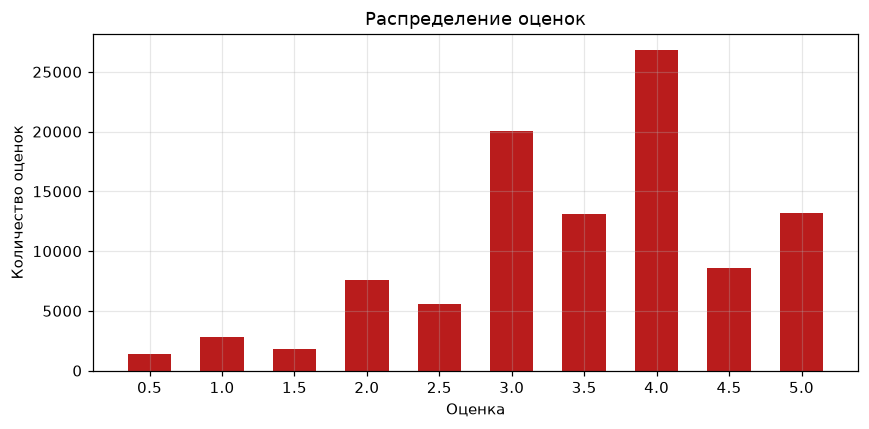

In [4]:
counts = ratings.rating.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index.astype(str), counts.values, color="#b91c1c", width=0.6)
ax.set_title("Распределение оценок")
ax.set_xlabel("Оценка")
ax.set_ylabel("Количество оценок")
fig.tight_layout()
fig.savefig(REPORTS / "01_ratings.png", dpi=150)
plt.show()

Больше половины оценок — это 3.5 и 4. Плохие оценки (0.5–1.5) встречаются заметно реже, то есть пользователи чаще ставят фильмам средние и хорошие баллы.

Теперь активность пользователей: сколько оценок приходится на одного человека.

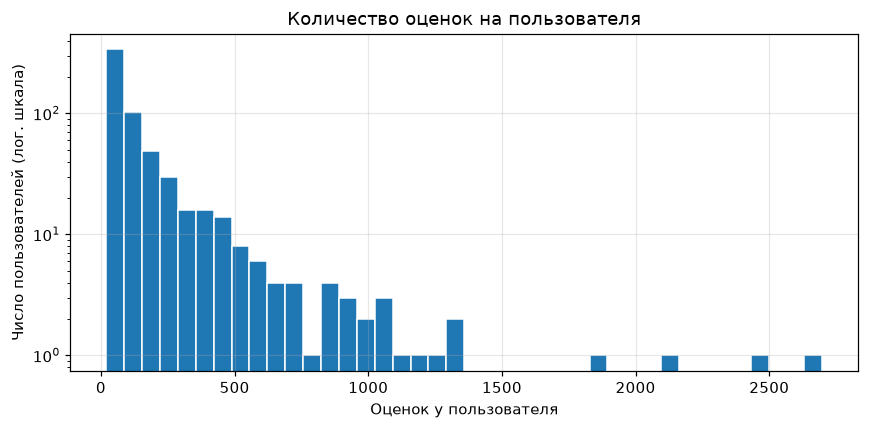

Минимум: 20, медиана: 70, максимум: 2698


In [5]:
per_user = ratings.groupby("user_id").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_user.values, bins=40, color="#1f77b4", edgecolor="white")
ax.set_yscale("log")
ax.set_title("Количество оценок на пользователя")
ax.set_xlabel("Оценок у пользователя")
ax.set_ylabel("Число пользователей (лог. шкала)")
fig.tight_layout()
fig.savefig(REPORTS / "02_users.png", dpi=150)
plt.show()

print(f"Минимум: {per_user.min()}, медиана: {int(per_user.median())}, максимум: {per_user.max()}")

Распределение сильно смещено вправо: у большинства пользователей меньше сотни оценок, но есть и очень активные, у которых больше тысячи. Для редких пользователей коллаборативная фильтрация работает хуже — это классическая проблема холодного старта.

Популярность фильмов и жанры.

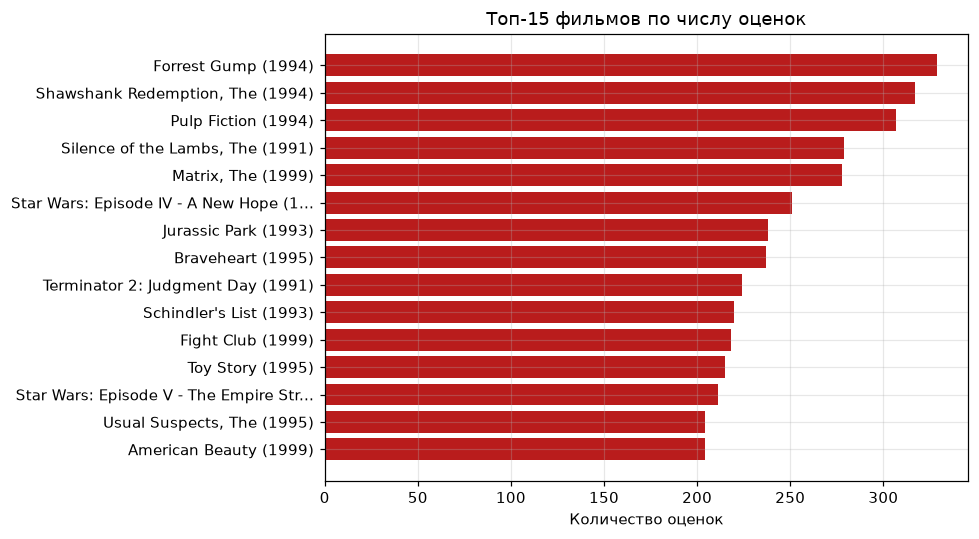

In [6]:
top_movies = (ratings.groupby("movie_id").size()
              .sort_values(ascending=False).head(15))
titles = movies.set_index("movie_id").title
labels = [t if len(t) <= 40 else t[:37] + "..." for t in titles[top_movies.index]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels[::-1], top_movies.values[::-1], color="#b91c1c")
ax.set_title("Топ-15 фильмов по числу оценок")
ax.set_xlabel("Количество оценок")
fig.tight_layout()
fig.savefig(REPORTS / "03_top_movies.png", dpi=150)
plt.show()

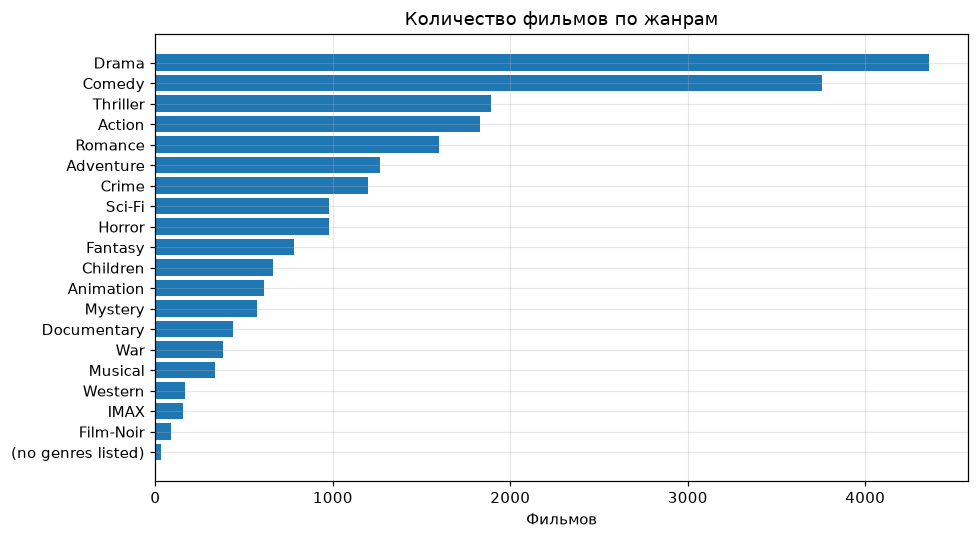

In [7]:
genre_counts = (movies.assign(genre=movies.genres.str.split("|"))
                .explode("genre").genre.value_counts())

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(genre_counts.index[::-1], genre_counts.values[::-1], color="#1f77b4")
ax.set_title("Количество фильмов по жанрам")
ax.set_xlabel("Фильмов")
fig.tight_layout()
fig.savefig(REPORTS / "04_genres.png", dpi=150)
plt.show()

Самый крупный жанр — драма, за ней идут комедия и триллер. Жанры используются в контентной модели: фильм описывается вектором жанров с весами TF-IDF.

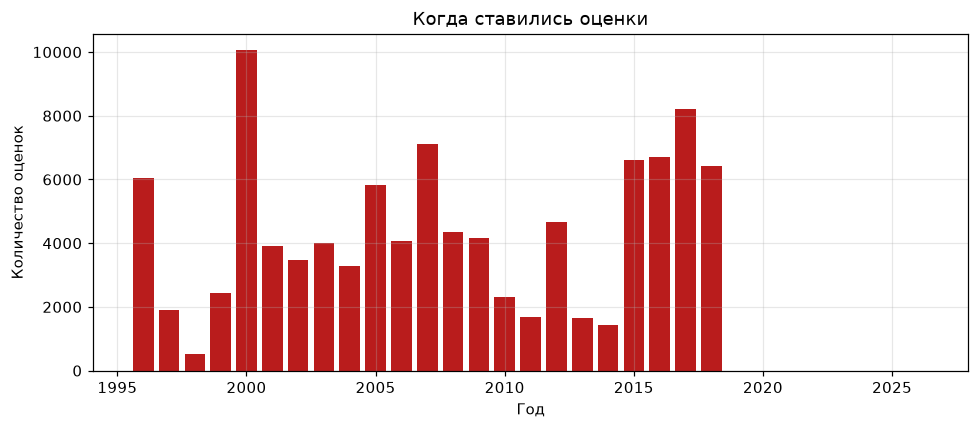

In [8]:
years = pd.to_datetime(ratings.timestamp, unit="s").dt.year
by_year = years.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_year.index, by_year.values, color="#b91c1c", width=0.8)
ax.set_title("Когда ставились оценки")
ax.set_xlabel("Год")
ax.set_ylabel("Количество оценок")
fig.tight_layout()
fig.savefig(REPORTS / "05_years.png", dpi=150)
plt.show()

## Модель

Модель реализована в `engine.py`. Все оценки центрируются на среднюю оценку пользователя: из каждой оценки вычитается его средняя, чтобы один человек, ставящий всем пятёрки, не считался похожим на всех подряд.

Похожесть пользователей и фильмов считается по косинусу на центрированных оценках. Для контентной модели строится TF-IDF по жанрам.

In [9]:
eng = engine.RecEngine()
eng.load()

print(f"Матрица оценок: {eng.matrix.shape[0]} пользователей x {eng.matrix.shape[1]} фильмов")
print(f"Заполнено: {eng.mask.sum()} ячеек")

Матрица оценок: 610 пользователей x 9724 фильмов
Заполнено: 100837 ячеек


Выберем самого активного пользователя: на нём удобно проверять рекомендации, потому что у него много оценок и соседи находятся уверенно.

In [10]:
active_user = int(ratings.user_id.value_counts().index[0])
user_ids = {row: uid for uid, row in eng.user_index.items()}
row = eng.user_index[active_user]

sims = eng.user_sim[row].copy()
sims[row] = -1

similar = np.argsort(-sims)[:5]
pd.DataFrame({
    "Пользователь": [user_ids[i] for i in similar],
    "Похожесть": [round(float(sims[i]), 3) for i in similar],
})

,Пользователь,Похожесть
0,599,0.276
1,480,0.208
2,288,0.201
3,368,0.196
4,590,0.193


## Примеры рекомендаций

Сначала посмотрим, что этот пользователь уже высоко оценил.

In [11]:
liked = (ratings[ratings.user_id == active_user]
         .sort_values("rating", ascending=False).head(10))
liked = liked.merge(movies, on="movie_id")[["title", "genres", "rating"]]
liked

,title,genres,rating
0,Baby Driver (2017),Action|Crime|Thriller,5.0
1,Band of Brothers (2001),Action|Drama|War,5.0
2,"American President, The (1995)",Comedy|Drama|Romance,5.0
3,Vertigo (1958),Drama|Mystery|Romance|Thriller,5.0
4,Rear Window (1954),Mystery|Thriller,5.0
5,Casablanca (1942),Drama|Romance,5.0
6,Roman Holiday (1953),Comedy|Drama|Romance,5.0
7,Citizen Kane (1941),Drama|Mystery,5.0
8,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,5.0
9,It's a Wonderful Life (1946),Children|Drama|Fantasy|Romance,5.0


Рекомендации по пользователям: берём 30 самых похожих пользователей, смотрим, что они оценили высоко, и усредняем с учётом похожести. Уже просмотренные фильмы исключаются.

In [12]:
def to_table(recs):
    if not recs:
        return pd.DataFrame()
    table = pd.DataFrame(recs)
    return table.rename(columns={"movieId": "ID", "title": "Фильм",
                                 "genres": "Жанры", "score": "Оценка"})

to_table(eng.user_based(active_user, 10))

,ID,Фильм,Жанры,Оценка
0,3030,Yojimbo (1961),Action|Adventure,1.693
1,3494,True Grit (1969),Adventure|Drama|Western,1.518
2,27156,Neon Genesis Evangelion: The End of Evangelion (Shin sei...,Action|Animation|Drama|Fantasy|Sci-Fi,1.518
3,1411,Hamlet (1996),Crime|Drama|Romance,1.384
4,3435,Double Indemnity (1944),Crime|Drama|Film-Noir,1.191
5,3358,Defending Your Life (1991),Comedy|Drama|Fantasy|Romance,1.183
6,307,Three Colors: Blue (Trois couleurs: Bleu) (1993),Drama,1.181
7,5833,Dog Soldiers (2002),Action|Horror,1.163
8,3468,"Hustler, The (1961)",Drama,1.135
9,1203,12 Angry Men (1957),Drama,1.087


Рекомендации по фильмам: для каждого фильма заранее найдены 40 самых похожих по оценкам. Кандидаты набираются из окрестностей фильмов, которые пользователь уже оценил.

In [13]:
to_table(eng.item_based(active_user, 10))

,ID,Фильм,Жанры,Оценка
0,911,Charade (1963),Comedy|Crime|Mystery|Romance|Thriller,1.315
1,3062,"Longest Day, The (1962)",Action|Drama|War,1.310
2,1248,Touch of Evil (1958),Crime|Film-Noir|Thriller,1.242
3,31658,Howl's Moving Castle (Hauru no ugoku shiro) (2004),Adventure|Animation|Fantasy|Romance,1.209
4,1258,"Shining, The (1980)",Horror,1.208
5,55167,Tekkonkinkreet (Tekkon kinkurîto) (2006),Action|Adventure|Animation|Crime|Fantasy,1.192
6,3429,Creature Comforts (1989),Animation|Comedy,1.177
7,1251,8 1/2 (8½) (1963),Drama|Fantasy,1.132
8,1230,Annie Hall (1977),Comedy|Romance,1.114
9,1219,Psycho (1960),Crime|Horror,1.105


Гибридный вариант объединяет два списка по правилу Reciprocal Rank Fusion: фильм получает балл 1 / (20 + позиция). Так учитывается и попадание в оба списка, и место в каждом из них.

In [14]:
to_table(eng.personal(active_user, 10))

,ID,Фильм,Жанры,Оценка
0,3030,Yojimbo (1961),Action|Adventure,0.0726
1,3062,"Longest Day, The (1962)",Action|Drama|War,0.0693
2,1248,Touch of Evil (1958),Crime|Film-Noir|Thriller,0.0639
3,27156,Neon Genesis Evangelion: The End of Evangelion (Shin sei...,Action|Animation|Drama|Fantasy|Sci-Fi,0.0591
4,3468,"Hustler, The (1961)",Drama,0.0553
5,1230,Annie Hall (1977),Comedy|Romance,0.0504
6,2186,Strangers on a Train (1951),Crime|Drama|Film-Noir|Thriller,0.0495
7,7132,"Night at the Opera, A (1935)",Comedy|Musical|Romance,0.0476
8,911,Charade (1963),Comedy|Crime|Mystery|Romance|Thriller,0.0476
9,3334,Key Largo (1948),Crime|Drama|Film-Noir|Thriller,0.0476


Отдельно проверим контентную модель: похожие фильмы по жанрам для фильма с самой высокой оценкой.

In [15]:
best_id = int(ratings[ratings.user_id == active_user]
              .sort_values("rating", ascending=False).movie_id.iloc[0])
print(movies.loc[movies.movie_id == best_id, "title"].iloc[0])
to_table(eng.content_based(best_id, 10))

Baby Driver (2017)


,ID,Фильм,Жанры,Оценка
0,189381,SuperFly (2018),Action|Crime|Thriller,1.0
1,6,Heat (1995),Action|Crime|Thriller,1.0
2,23,Assassins (1995),Action|Crime|Thriller,1.0
3,4855,Dirty Harry (1971),Action|Crime|Thriller,1.0
4,26736,Riki-Oh: The Story of Ricky (Lik Wong) (1991),Action|Crime|Thriller,1.0
5,6874,Kill Bill: Vol. 1 (2003),Action|Crime|Thriller,1.0
6,58826,"Shepherd: Border Patrol, The (2008)",Action|Crime|Thriller,1.0
7,94405,Safe (2012),Action|Crime|Thriller,1.0
8,99112,Jack Reacher (2012),Action|Crime|Thriller,1.0
9,27022,Thursday (1998),Action|Crime|Thriller,1.0


Матрица схожести десяти самых популярных фильмов по жанровым векторам. Видно, что похожими оказываются фильмы с общим набором жанров, например боевики и приключения.

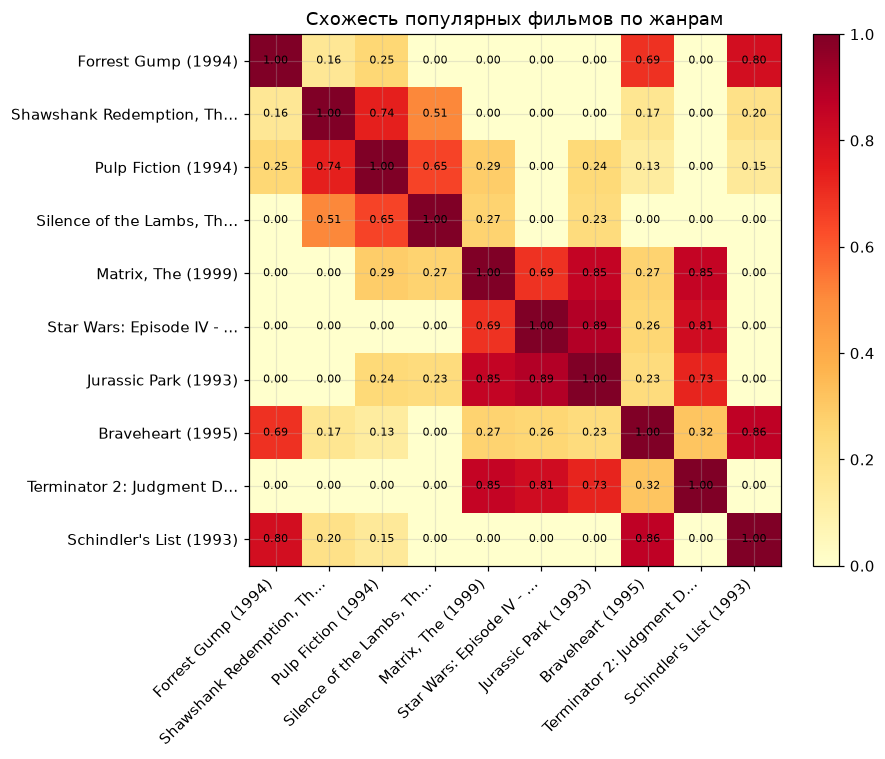

In [16]:
top_ids = ratings.groupby("movie_id").size().sort_values(ascending=False).index[:10]
top_ids = [m for m in top_ids if m in eng.movie_row]
vecs = eng.content_vecs[[eng.movie_row[m] for m in top_ids]]
sim_matrix = vecs @ vecs.T
labels = [eng.titles[m][:24] + ("..." if len(eng.titles[m]) > 24 else "") for m in top_ids]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(sim_matrix, cmap="YlOrRd", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{sim_matrix[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Схожесть популярных фильмов по жанрам")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(REPORTS / "06_similarity.png", dpi=150)
plt.show()

## Оценка качества

Качество проверяется по схеме leave-one-out: у каждого пользователя откладывается последняя по времени высокая оценка (не ниже 3.5), остальные оценки идут в обучение. Модель обучается заново только на обучающей части, затем для пользователя строится список из 10 рекомендаций, и проверяется, попал ли в него отложенный фильм.

Учитываются только фильмы, которые человеку действительно понравились: рекомендовать фильм, которому он поставил 1, и считать это попаданием неправильно.

Считаются метрики:
- **HR@10** — доля пользователей, у которых отложенный фильм попал в топ-10;
- **Precision@10** — доля правильных фильмов в выдаче;
- **MRR@10** — средний обратный ранг правильного фильма;
- **Покрытие** — какая доля каталога встречается в рекомендациях.

Для сравнения добавлена базовая линия из самых популярных фильмов.

In [17]:
liked_ratings = ratings[ratings.rating >= 3.5]
test = liked_ratings.sort_values(["user_id", "timestamp"]).groupby("user_id").tail(1)
train = ratings.drop(test.index)

train_counts = train.user_id.value_counts()
test_movie = dict(zip(test.user_id, test.movie_id))

movies_tuples = list(movies[["movie_id", "title", "genres"]].itertuples(index=False, name=None))
train_tuples = list(train[["user_id", "movie_id", "rating"]].itertuples(index=False, name=None))

# модель должна видеть только обучающую часть, поэтому временно подменяем загрузку данных
original_get_all = database.get_all
database.get_all = lambda: (movies_tuples, train_tuples)
eval_engine = engine.RecEngine()
eval_engine.load()
database.get_all = original_get_all

eval_users = [u for u in test.user_id.unique()
              if train_counts.get(u, 0) >= 20 and test_movie[u] in eval_engine.movie_index]
print(f"Оценок в обучении: {len(train)}, отложено: {len(test)}")
print(f"Пользователей в оценке: {len(eval_users)}")

Оценок в обучении: 100228, отложено: 609
Пользователей в оценке: 581


In [18]:
popular_counts = train.groupby("movie_id").size().sort_values(ascending=False)
popular_ids = [m for m in popular_counts.index if m in eval_engine.movie_index]


def popular_recs(user_id, limit=10):
    seen = set(train.loc[train.user_id == user_id, "movie_id"])
    return [m for m in popular_ids if m not in seen][:limit]


K = 10
results = {"Популярные": {}, "User-based": {}, "Item-based": {}, "Гибрид": {}}
times = {name: [] for name in results}

for i, user_id in enumerate(eval_users, 1):
    t0 = time.perf_counter()
    recs = popular_recs(user_id, K)
    times["Популярные"].append(time.perf_counter() - t0)
    results["Популярные"][user_id] = recs

    for name, method in [("User-based", eval_engine.user_based),
                         ("Item-based", eval_engine.item_based),
                         ("Гибрид", eval_engine.personal)]:
        t0 = time.perf_counter()
        recs = method(user_id, K) or []
        times[name].append(time.perf_counter() - t0)
        results[name][user_id] = [r["movieId"] for r in recs]

    if i % 100 == 0:
        print(f"обработано {i} из {len(eval_users)}")

обработано 100 из 581


обработано 200 из 581


обработано 300 из 581


обработано 400 из 581


обработано 500 из 581


In [19]:
def evaluate(recs_by_user):
    hits = 0
    reciprocal = 0.0
    covered = set()
    for user_id, recs in recs_by_user.items():
        covered.update(recs)
        target = test_movie[user_id]
        if target in recs:
            hits += 1
            reciprocal += 1.0 / (recs.index(target) + 1)
    n = len(recs_by_user)
    return {
        "HR@10": hits / n,
        "Precision@10": hits / (n * K),
        "MRR@10": reciprocal / n,
        "Покрытие": len(covered) / len(eval_engine.movie_index),
    }


rows = []
for name, recs_by_user in results.items():
    row = evaluate(recs_by_user)
    row["Алгоритм"] = name
    row["Время, мс"] = round(float(np.mean(times[name])) * 1000, 2)
    rows.append(row)

metrics = pd.DataFrame(rows).set_index("Алгоритм")
metrics = metrics[["HR@10", "Precision@10", "MRR@10", "Покрытие", "Время, мс"]]
metrics.round(4).to_csv(REPORTS / "metrics.csv", encoding="utf-8-sig")
metrics.round(4)

,HR@10,Precision@10,MRR@10,Покрытие,"Время, мс"
Алгоритм,,,,,
Популярные,0.0516,0.0052,0.0183,0.0124,0.96
User-based,0.0275,0.0028,0.0066,0.0928,1.64
Item-based,0.0327,0.0033,0.0091,0.1808,5.98
Гибрид,0.0430,0.0043,0.0152,0.1368,7.85


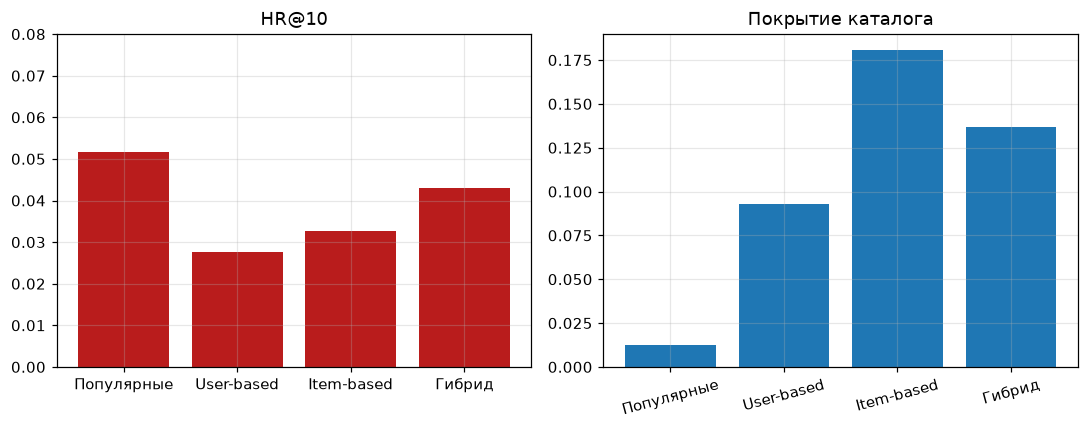

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(metrics.index, metrics["HR@10"], color="#b91c1c")
axes[0].set_title("HR@10")
axes[0].set_ylim(0, max(0.08, metrics["HR@10"].max() * 1.3))

axes[1].bar(metrics.index, metrics["Покрытие"], color="#1f77b4")
axes[1].set_title("Покрытие каталога")
axes[1].tick_params(axis="x", rotation=15)

fig.tight_layout()
fig.savefig(REPORTS / "07_metrics.png", dpi=150)
plt.show()

Посмотрим отдельно, как методы ведут себя на пользователях с разной активностью. Для новых пользователей данных мало, для очень активных — наоборот, почти всё популярное уже просмотрено.

In [21]:
def activity_group(n):
    if n < 50:
        return "20-49"
    if n < 200:
        return "50-199"
    return "200+"


rows = []
for group in ["20-49", "50-199", "200+"]:
    row = {"Оценок у пользователя": group}
    for name, recs_by_user in results.items():
        group_users = [u for u in recs_by_user if activity_group(int(train_counts[u])) == group]
        hits = sum(1 for u in group_users if test_movie[u] in recs_by_user[u])
        row[name] = round(hits / len(group_users), 4) if group_users else np.nan
    rows.append(row)

activity = pd.DataFrame(rows).set_index("Оценок у пользователя")
activity.to_csv(REPORTS / "activity.csv", encoding="utf-8-sig")
activity

,Популярные,User-based,Item-based,Гибрид
Оценок у пользователя,,,,
20-49,0.0599,0.0369,0.0553,0.0553
50-199,0.0455,0.0248,0.0248,0.0455
200+,0.0492,0.0164,0.0082,0.0164


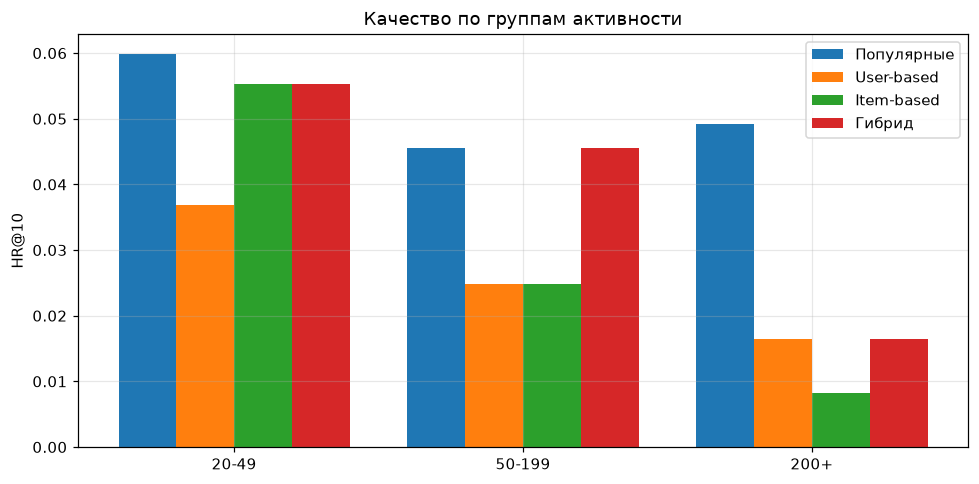

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(activity.index))
width = 0.2

for i, name in enumerate(results):
    ax.bar(positions + (i - 1.5) * width, activity[name], width=width, label=name)

ax.set_xticks(positions, activity.index)
ax.set_ylabel("HR@10")
ax.set_title("Качество по группам активности")
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / "08_activity.png", dpi=150)
plt.show()

### Проверка на случайном разбиении

Одна отложенная оценка на пользователя — шумная проверка. Для устойчивости повторим эксперимент на случайном разбиении: 80 % оценок в обучение, 20 % в тест (только оценки не ниже 3.5). Считаем **Recall@10** — какую долю отложенных фильмов пользователя модель нашла в топ-10.

In [23]:
rng = np.random.default_rng(42)
order = rng.permutation(len(ratings))
split = int(len(ratings) * 0.8)

train2 = ratings.iloc[order[:split]]
test2 = ratings.iloc[order[split:]]
test2 = test2[test2.rating >= 3.5]

train2_tuples = list(train2[["user_id", "movie_id", "rating"]].itertuples(index=False, name=None))
database.get_all = lambda: (movies_tuples, train2_tuples)
eng2 = engine.RecEngine()
eng2.load()
database.get_all = original_get_all

test2_map = {u: [m for m in ms if m in eng2.movie_index]
             for u, ms in test2.groupby("user_id").movie_id.apply(list).items()}
test2_map = {u: ms for u, ms in test2_map.items() if ms and u in eng2.user_index}
print(f"Обучение: {len(train2)}, тест: {len(test2)}, пользователей: {len(test2_map)}")

Обучение: 80669, тест: 12425, пользователей: 596


In [24]:
pop2_counts = train2.groupby("movie_id").size().sort_values(ascending=False)
pop2_ids = [m for m in pop2_counts.index if m in eng2.movie_index]


def popular_recs2(user_id, limit=10):
    seen = set(train2.loc[train2.user_id == user_id, "movie_id"])
    return [m for m in pop2_ids if m not in seen][:limit]


rows = []
for name, method in [("Популярные", None),
                     ("User-based", eng2.user_based),
                     ("Item-based", eng2.item_based),
                     ("Гибрид", eng2.personal)]:
    found = 0.0
    covered = set()
    spent = 0.0
    for user_id, targets in test2_map.items():
        t0 = time.perf_counter()
        recs = popular_recs2(user_id, K) if method is None else             [r["movieId"] for r in (method(user_id, K) or [])]
        spent += time.perf_counter() - t0
        covered.update(recs)
        found += len(set(recs) & set(targets)) / len(targets)
    n = len(test2_map)
    rows.append({"Алгоритм": name,
                 "Recall@10": found / n,
                 "Покрытие": len(covered) / len(eng2.movie_index),
                 "Время, мс": spent / n * 1000})

random_metrics = pd.DataFrame(rows).set_index("Алгоритм")
random_metrics.round(4).to_csv(REPORTS / "metrics_random.csv", encoding="utf-8-sig")
random_metrics.round(4)

,Recall@10,Покрытие,"Время, мс"
Алгоритм,,,
Популярные,0.0959,0.0057,0.5846
User-based,0.0417,0.0901,1.3582
Item-based,0.0344,0.1974,5.1995
Гибрид,0.0592,0.1475,7.9306


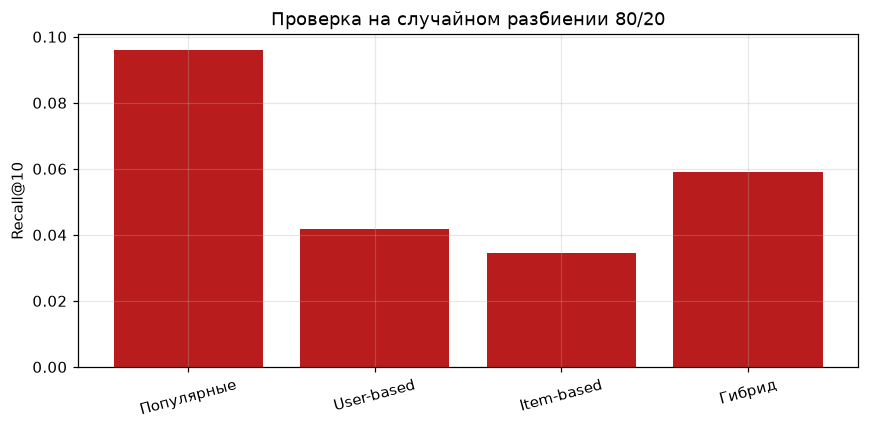

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(random_metrics.index, random_metrics["Recall@10"], color="#b91c1c")
ax.set_ylabel("Recall@10")
ax.set_title("Проверка на случайном разбиении 80/20")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(REPORTS / "09_random_split.png", dpi=150)
plt.show()

## Выводы

1. Собрана рекомендательная система для MovieLens: популярные фильмы, user-based, item-based и гибрид через RRF. Все методы работают быстро — на одного пользователя уходит меньше 10 мс.
2. Проверка leave-one-out (581 пользователь, отложена последняя оценка не ниже 3.5) дала такие результаты: популярные фильмы — HR@10 = 5,2 %, гибрид — 4,3 %, item-based — 3,3 %, user-based — 2,8 %. Базовая линия впереди, и это ожидаемо: данных мало (плотность матрицы 1,7 %), а последняя оценка активного пользователя часто приходится на известный фильм.
3. Среди персональных методов лучше всего показал себя гибрид: у него максимальные HR@10 и MRR@10 (1,52 %). Item-based даёт самый широкий охват каталога — 18,1 % против 1,2 % у популярных, то есть пользователи получают разные фильмы, а не один и тот же топ.
4. По группам активности: у новичков (20–49 оценок) лучше популярные — 6,0 % против 5,5 % у гибрида и item-based; в группе 50–199 гибрид сравнивается с популярными (4,6 %); у самых активных персональные методы проседают (1,6 % у user-based и гибрида), потому что почти всё популярное уже просмотрено и отложенный фильм предсказать сложнее.
5. На случайном разбиении 80/20 картина сохраняется: Recall@10 у популярных 9,6 %, у гибрида 5,9 %, у user-based 4,2 %, у item-based 3,4 %. При этом item-based охватывает 19,7 % каталога, гибрид — 14,8 %, популярные — 0,6 %.
6. Для приложения выбран гибрид: он лучший среди персональных методов и даёт компромисс между качеством и разнообразием. Новому пользователю без оценок показывается подборка популярных фильмов, а на карточке фильма работает контентная модель по жанрам.
7. Ограничения работы: одна отложенная оценка на пользователя, в качестве сигнала используются только оценки, не учитываются время просмотра и признаки фильмов кроме жанров.

**Источники**
1. MovieLens Latest Datasets — GroupLens Research, University of Minnesota.
2. Ricci F., Rokach L., Shapira B. Recommender Systems Handbook. Springer, 2015.
3. Koren Y., Bell R., Volinsky C. Matrix Factorization Techniques for Recommender Systems. Computer, 2009.